### **1.Setup**

In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
from IPython.display import display
import math

train_path=os.path.join("..","data","raw","train.csv")

### **2.Loading Data and First Look**

#### **2.1. Overall First Look**

In [3]:
df_raw= pd.read_csv(train_path,index_col="ID",sep=",")
print(f"Rows:{df_raw.shape[0]:,} | Columns:{df_raw.shape[1]}")
df_raw.head().T

Rows:6,534 | Columns:38


ID,10000000,10000001,10000002,10000003,10000004
Total a Pagar,558.11,978.8,10.33,856.83,1616.1
Total Bruto,510.9,830.02,12.0,696.61,1488.85
Total Liquido,453.75,795.77,8.4,696.61,1313.9
Total Imp_,104.36,183.03,1.93,160.22,302.2
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95
Custo,153.099911,472.943134,6.097485,408.167275,485.401864
N_ Detalhes,4.0,32.0,1.0,9.0,33.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


In [4]:
#df_raw.info() shows the type of each column
df_raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

Purchase Date as String is a problem

#### **2.2 Grouping the Variables**

To better organize our data we chose to group the variables by themes:

In [5]:
#Variables with special structural roles
target_col = "repeat_purchase_90d"
group_col = "customer_id"
index_col = "ID"

# Grouping by themes
var_groups = {
    "Identifier": [
        "ID",
        "customer_id"
    ],
    "Target": [
        "repeat_purchase_90d"
    ],
    "Current transaction (financial)": [
        "Total a Pagar",
        "Total Bruto",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Custo"
    ],
    "Current transaction (operational)": [
        "N_ Detalhes",
        "invoice_count_current_purchase"
    ],
    "Transaction context & date": [
        "purchase_date",
        "payment_type",
        "salesperson",
        "commercial_zone",
        "warehouse",
        "document_series",
        "transport_method"
    ],
    "Customer historical summary": [
        "customer_tenure_days",
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ],
    "Customer cadence & gaps": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "prior_std_gap_days"
    ],
    "Rolling windows (RFM)": [
        "purchase_count_30d",
        "spend_30d",
        "purchase_count_90d",
        "spend_90d",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ],
    "Synthetic / Control": [
        "random_noise"
    ]
}
pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()], columns=["Group", "# vars", "Variables"])

,Group,# vars,Variables
0,Identifier,2,"ID, customer_id"
1,Target,1,repeat_purchase_90d
2,Current transaction (financial),8,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
3,Current transaction (operational),2,"N_ Detalhes, invoice_count_current_purchase"
4,Transaction context & date,7,"purchase_date, payment_type, salesperson, comm..."
5,Customer historical summary,7,"customer_tenure_days, prior_purchase_count, pr..."
6,Customer cadence & gaps,3,"days_since_previous_purchase, prior_mean_gap_d..."
7,Rolling windows (RFM),8,"purchase_count_30d, spend_30d, purchase_count_..."
8,Synthetic / Control,1,random_noise


#### **2.3.The Target and the Floor**


In [40]:
balance = df_raw[target_col].value_counts().sort_index()
print(balance.to_frame("rows").assign(share=lambda f: (f["rows"] / f["rows"].sum()).round(3)).to_string())

# The two floors: always predict the majority class (accuracy), and always predict 1 (F1 of class 1).
p = df_raw[target_col].mean()
print(f"\nalways predict 1 -> accuracy {p:.3f} | F1(class 1) {2 * p / (1 + p):.3f}")
print(f"always predict 0 -> accuracy {1 - p:.3f} | F1(class 1) 0.000")


                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

always predict 1 -> accuracy 0.559 | F1(class 1) 0.717
always predict 0 -> accuracy 0.441 | F1(class 1) 0.000


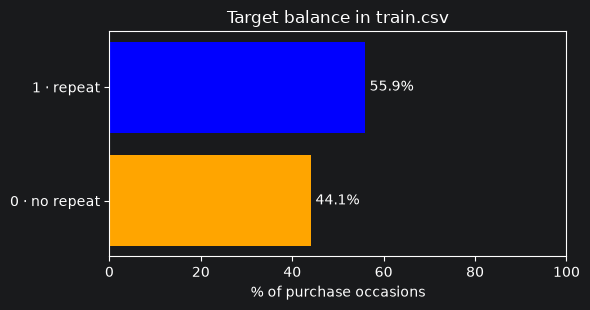

In [43]:
fig, ax = plt.subplots(figsize=(6, 3.2))
shares = df_raw[target_col].value_counts(normalize=True).sort_index() * 100
ax.barh(["0 · no repeat", "1 · repeat"], shares.values, color=["orange", "blue"])
for i, v in enumerate(shares.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set(xlim=(0, 100), xlabel="% of purchase occasions", title="Target balance in train.csv")
plt.tight_layout()
plt.show()

**What this tells us**

* The classes are **mildly imbalanced, and class 1 is the majority** (≈56%). That is unusual: in most screening
  problems the positive class is rare.
* Because the competition scores the **F1 of class 1**, the trivial model "everybody comes back" already scores
  **F1 ≈ 0.72**. F1 ignores true negatives, so predicting 1 is cheap and missing a 1 is expensive.
* Two consequences for later: (1) every F1 we report will be compared with the all-ones floor, and
  (2) the decision **threshold** is part of the model. The default 0.5 is not necessarily the one that maximises F1.
* Resampling (SMOTE, undersampling) is not needed: the minority class still has ≈2,900 rows.

###  **3. Data Quality Assessment**

  Before changing anything, we first diagnose the problems.

#### **3.1. Rows with no information**

Before looking at each column, we look at each row, to see how much information each row gives us.

In [6]:
row_missing_percentage = pd.DataFrame({
    'customer_id': df_raw['customer_id'],
    'n_missing': df_raw.isna().sum(axis=1),
    'pct_missing': (df_raw.isna().sum(axis=1) * 100) / df_raw.shape[1]})

row_missing_percentage = (
    row_missing_percentage
    .set_index("customer_id")
    .query("n_missing > 19")
    .sort_values("n_missing", ascending=False))

print(f"There are {row_missing_percentage.shape[0]} rows with at least 50% of missing values")
row_missing_percentage

There are 65 rows with at least 50% of missing values


,n_missing,pct_missing
customer_id,,
755628,36,94.736842
755628,36,94.736842
427118,36,94.736842
508217,36,94.736842
427118,36,94.736842
...,...,...
151492,36,94.736842
230585,36,94.736842
902830,36,94.736842


In [7]:
# rows where everything is missing except customer_id and the target
empty_rows = df_raw.drop(columns=["customer_id", "repeat_purchase_90d"]).isna().all(axis=1)
print(f"Empty rows: {empty_rows.sum()}")

# df is our working copy without the empty rows (df_raw stays untouched)
df = df_raw.loc[~empty_rows]
print(f"Rows in df: {df.shape[0]:,}")

Empty rows: 65
Rows in df: 6,469


There are 65 rows with more than 50% of missing values, and in fact they only have `customer_id` and the target. We **consider them disposable because they do not give us enough information**, so from now on we analyse `df`, which is `df_raw` without these 65 rows.

#### **3.2. Duplicates**

In [8]:
n_dup_rows=df_raw.duplicated().sum()  #rows that are 100% identical in the raw file
print(f"Fully duplicated rows (raw file): {n_dup_rows}")
print(f"Fully duplicated rows (without the empty rows): {df.duplicated().sum()}")

n_dup_ids=df["customer_id"].duplicated().sum() #repeated client IDs
n_client_ids= df["customer_id"].nunique()
print(f"Duplicated client_id  : {n_dup_ids}")
print(f"Number of clients : {n_client_ids}")
print(f"Number of receipts/clients: {(len(df)/n_client_ids):.2f}")

Fully duplicated rows (raw file): 10
Fully duplicated rows (without the empty rows): 0
Duplicated client_id  : 5862
Number of clients : 607
Number of receipts/clients: 10.66


In the raw file there are 10 fully duplicated rows, but they are all empty rows: two empty rows of the same client look the same. Without the empty rows there are **no duplicated purchases**.

The repeated `customer_id` is not a problem: there are 6,469 purchases from 607 clients, about 10.7 purchases per client. This means the rows of the same client are not independent, which we have to keep in mind when we split the data for validation.

#### **3.3. Missing Values**

In [9]:
missing_values=(df.isna().sum().to_frame("n_missing").assign(percentage=lambda x: (x["n_missing"]*100/len(df))).query("n_missing>0").sort_values("percentage", ascending=False))
missing_values

,n_missing,percentage
prior_std_gap_days,1413,21.842634
prior_mean_gap_days,1243,19.214716
prior_std_purchase_value,1048,16.200340
prior_mean_purchase_value,797,12.320297
days_since_previous_purchase,796,12.304838
prior_min_purchase_value,603,9.321379
prior_max_purchase_value,603,9.321379
transport_method,196,3.029835
spend_365d,195,3.014376
payment_type,195,3.014376


In [10]:
# Hypothesis 1: history columns are missing because the customer has (almost) no history.
history_missing = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                   "prior_min_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = df["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
table = (df[history_missing].isna()
         .groupby(prior_n).mean().mul(100).round(1)
         .assign(rows=prior_n.value_counts()))
table.index.name = "prior purchases"
table

,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_mean_gap_days,prior_std_gap_days,rows
prior purchases,,,,,,,
0,100.0,100.0,100.0,100.0,100.0,100.0,603
1,4.3,4.5,100.0,0.0,100.0,100.0,445
2,5.5,3.0,0.0,0.0,5.8,100.0,365
3+,3.0,3.2,0.0,0.0,3.4,0.0,5056


The hypothesis holds **only in part**:

* With **0 prior purchases**, every history column is missing in 100% of rows, as expected: there is no history.
* With **1 prior purchase**, the gap and the standard deviations are always missing (one purchase has no gap and no
  spread), but `days_since_previous_purchase` should exist, and it is still missing for a fraction of rows.
* With **2 or more** prior purchases, all these columns *should* exist, yet a few percent are missing anyway. That
  part is ordinary missingness, not structural.

So "missing = no history" (the business-logic reading, MNAR) explains most but not all of it. This decides the fix: we
add an explicit flag such as `is_first_purchase` (`prior_purchase_count == 0`) and *missing indicators*, then impute
the remaining gaps with the **training median**. We do **not** fill gaps with 0: a gap of 0 days would mean "buys every
day", which is the opposite of "no history".

Without the empty rows, the invoice columns, `commercial_zone`, `document_series`, `purchase_date` and the rolling windows have **no missing values**. The real missing values are only in the history columns and in some context columns (about 3% each).

Some history columns have around 20% of missing values, but we do **not** drop them: the missing values are mostly structural (clients without previous purchases), and these columns are among the most important ones for the target (for example `prior_mean_gap_days`). Dropping them would lose a lot of information.

#### **3.4. Inconsistent Categories**

In [11]:
cat_cols = df.select_dtypes(include=['object', 'category', 'str']).columns.tolist()
cat_cols.remove("purchase_date")  # it is a date, not a category
for col in cat_cols:
    print(f"{col:<10} -> {df[col].nunique()} distinct values")

payment_type -> 9 distinct values
salesperson -> 9 distinct values
commercial_zone -> 5 distinct values
transport_method -> 80 distinct values
warehouse  -> 2 distinct values
document_series -> 3 distinct values


Each category is always written in the same way, so there are no spelling variants to fix. The real problem is the **rare levels**: some levels appear only a few times (for example `commercial_zone` 6 and 7 with 1 row each, and many `transport_method` levels with only 1 row). Lets look at each column.

In [12]:
df["payment_type"].value_counts(dropna=False)

payment_type
Maybe Tomorrow Payment 7     4565
Maybe Tomorrow Payment 12     991
Maybe Tomorrow Payment 9      502
NaN                           195
Maybe Tomorrow Payment 10     134
Maybe Tomorrow Payment 8       40
Maybe Tomorrow Payment 2       21
Maybe Tomorrow Payment 4        9
Maybe Tomorrow Payment 11       8
Maybe Tomorrow Payment 3        4
Name: count, dtype: int64

In [13]:
df[("salesperson")].value_counts(dropna=False)

salesperson
VLOOKUP Master 1    4054
VLOOKUP Master 4    1461
VLOOKUP Master 9     384
VLOOKUP Master 7     201
NaN                  194
VLOOKUP Master 2     123
VLOOKUP Master 3      30
VLOOKUP Master 6      12
VLOOKUP Master 5       7
VLOOKUP Master 8       3
Name: count, dtype: int64

In [14]:
df[("commercial_zone")].value_counts(dropna=False)

commercial_zone
Decorative Dashboard Zone 4    6260
Decorative Dashboard Zone 2     151
Decorative Dashboard Zone 3      56
Decorative Dashboard Zone 6       1
Decorative Dashboard Zone 7       1
Name: count, dtype: int64

This category is fine and has no missing values once the empty rows are removed. Zones 6 and 7 only have 1 row each, so they are rare levels.

In [15]:
df["transport_method"].isna().sum()
print(f"There are {df["transport_method"].isna().sum()} NaNs in this category")
df["transport_method"].value_counts(dropna=False)

There are 196 NaNs in this category


transport_method
Maybe Tomorrow Delivery 72    1119
Maybe Tomorrow Delivery 61     627
Maybe Tomorrow Delivery 73     445
Maybe Tomorrow Delivery 59     373
Maybe Tomorrow Delivery 80     319
                              ... 
Maybe Tomorrow Delivery 55       1
Maybe Tomorrow Delivery 58       1
Maybe Tomorrow Delivery 28       1
Maybe Tomorrow Delivery 21       1
Maybe Tomorrow Delivery 23       1
Name: count, Length: 81, dtype: int64

In [16]:
df[("warehouse")].value_counts(dropna=False)

warehouse
Final Excel Warehouse 1    6253
NaN                         195
Final Excel Warehouse 3      21
Name: count, dtype: int64

In [17]:
df[("document_series")].value_counts(dropna=False)

document_series
Ctrl Z Series 2    2738
Ctrl Z Series 3    1903
Ctrl Z Series 1    1828
Name: count, dtype: int64

In [18]:
df[("purchase_date")].value_counts(dropna=False)

purchase_date
2015-10-31    52
2018-08-05    46
2016-07-17    42
2015-07-12    41
2018-07-21    40
              ..
2021-09-03     1
2024-01-14     1
2023-09-11     1
2022-02-18     1
2024-03-13     1
Name: count, Length: 1492, dtype: int64

#### **3.5. Wrong Data Types**

#### **3.5.1. Dates**

In [19]:
# Date columns: check which formats are used by replacing every digit with "9"
patterns = df["purchase_date"].astype(str).str.replace(r"\d", "9", regex=True).value_counts()
print(f"{"date format":<18}", patterns.to_dict())
print(f"{"missing values":<18}", df[("purchase_date")].isna().sum())

date format        {'9999-99-99': 6469}
missing values     0


The dates are all in the format 9999-99-99, and there are no missing dates once the empty rows are removed.

#### **3.6. Impossible Values**

In [20]:
cols_num = df.select_dtypes(include=["number"]).columns.tolist()
df[cols_num].describe().T[["min","25%","50%","75%","max"]].round(2)

,min,25%,50%,75%,max
Total a Pagar,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,0.00,0.00,13.13,92.28,4.103440e+03
Custo,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,1.00,1.00,1.00,1.00,5.000000e+00


Three things cannot be true:

* `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** (one billion euros), while their medians are
  ≈725 € and ≈2,400 €.
* `days_since_previous_purchase` and `prior_mean_gap_days` have **negative** values (a gap cannot be negative), and
  `prior_mean_purchase_value` and `spend_365d` too (spending cannot be negative).

Random damage would scatter over many values. Placeholders sit on a few exact values, so we look at the values themselves.

In [21]:
checks = {
    "prior_mean_purchase_value": df["prior_mean_purchase_value"],
    "spend_365d": df["spend_365d"],
    "days_since_previous_purchase": df["days_since_previous_purchase"],
    "prior_mean_gap_days": df["prior_mean_gap_days"],
}
for name, s in checks.items():
    bad = s[(s < 0) | (s >= 1e8)]
    print(f"{name:30s} {len(bad):3d} impossible values -> {bad.value_counts().head(4).to_dict()}")

prior_mean_purchase_value       32 impossible values -> {1000000000.0: 16, -110.14709677419351: 1, -409.7916666666667: 1, -218.2663917525773: 1}
spend_365d                      30 impossible values -> {1000000000.0: 15, -3456.32: 1, -1230.72: 1, -167.18: 1}
days_since_previous_purchase    16 impossible values -> {-4.0: 16}
prior_mean_gap_days             16 impossible values -> {-4.0: 16}


We have observed that the values 1e9 and -4 are exact repeated values, so they look like codes and not real values. They are impossible values considering the financial context. Before deciding what to do, we check if the real value can be recovered from other columns.

##### **3.6.1. Impossible Values of "Prior_mean_purchase_value"**

Lets examinate the negative values of "prior_mean_purchase_value":

In [22]:
df[df["prior_mean_purchase_value"]<0].T

ID,10000018,10000519,10000536,10001157,10001375,10001461,10002281,10002605,10002989,10003383,10003794,10003949,10005413,10006099,10006217,10006219
Total a Pagar,2460.0,221.74,4.65,473.82,423.46,105.29,43.01,2923.88,377.3,93.81,491.61,56.79,502.17,27.8,144.13,592.97
Total Bruto,2000.0,180.28,5.4,447.0,646.53,122.28,49.95,2587.5,409.0,88.5,399.68,54.52,472.96,22.6,117.18,791.45
Total Liquido,2000.0,180.28,3.78,447.0,344.28,85.6,34.97,2587.5,306.75,88.5,399.68,46.17,408.27,22.6,117.18,482.09
Total Imp_,460.0,41.46,0.87,26.82,79.18,19.69,8.04,336.38,70.55,5.31,91.93,10.62,93.9,5.2,26.95,110.88
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.1,3.1,5.6,0.0,0.0,4.2
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,0.0,0.0,1.62,0.0,302.25,36.68,14.98,0.0,102.25,0.0,0.0,8.35,64.69,0.0,0.0,309.36
Custo,0.0,140.628,2.97,289.5,149.968648,61.08,16.29,0.0,123.74,57.9,227.21,3.56634,150.857,17.78,57.811668,189.475636
N_ Detalhes,1.0,6.0,1.0,58.0,30.0,3.0,1.0,1.0,3.0,8.0,14.0,3.0,10.0,2.0,7.0,44.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [23]:
recomputed_mean = df["prior_total_spend"] / df["prior_purchase_count"].replace(0, np.nan)
stored_mean = df["prior_mean_purchase_value"]

is_billion = stored_mean >= 1e8
is_negative = stored_mean < 0
is_normal = stored_mean.notna() & ~is_billion & ~is_negative
pd.DataFrame({
    "prior_total_spend": df.loc[is_negative, "prior_total_spend"],
    "prior_purchase_count": df.loc[is_negative, "prior_purchase_count"],
    "total / count": recomputed_mean[is_negative],
    "stored prior_mean_purchase_value": stored_mean[is_negative],
}).head(5).round(2)

,prior_total_spend,prior_purchase_count,total / count,stored prior_mean_purchase_value
ID,,,,
10000018,3414.56,31.0,110.15,-110.15
10000519,2458.75,6.0,409.79,-409.79
10000536,42343.68,194.0,218.27,-218.27
10001157,2925.42,7.0,417.92,-417.92
10001375,3895.15,5.0,779.03,-779.03


**The 16 negative values are a sign error**: in every one of them, the stored value is exactly
  `−(prior_total_spend / prior_purchase_count)`. There is no business logic behind a negative mean.

In [24]:
pd.DataFrame({
    "rows": [is_normal.sum(), is_negative.sum(), is_billion.sum()],
    "stored = total / count": [np.isclose(stored_mean[m], recomputed_mean[m]).mean()
                               for m in (is_normal, is_negative, is_billion)],
    "|stored| = total / count": [np.isclose(stored_mean[m].abs(), recomputed_mean[m]).mean()
                                 for m in (is_normal, is_negative, is_billion)],
    "total / count can be computed": [recomputed_mean[m].notna().mean()
                                      for m in (is_normal, is_negative, is_billion)],
}, index=["normal values", "negative values", "1e9 values"]).round(3)

,rows,stored = total / count,|stored| = total / count,total / count can be computed
normal values,5640,0.992,0.992,1.0
negative values,16,0.000,1.000,1.0
1e9 values,16,0.000,0.000,1.0


**The formula holds**: for 99.2% of the normal rows, the stored mean is exactly total / count.

**The 16 values of 1e9 can be recovered as well**: all these customers have previous purchases, so total / count can
  be computed for every one of them.

#### 3.6.2 And the negative values of `spend_365d`?

`spend_365d` cannot be recomputed from other columns, but it must respect two bounds: it includes the last 180 days, so
it is at least `spend_180d`, and it is part of the whole history, so it is at most `prior_total_spend`. We check
whether the negative values fit these bounds once the sign is removed.

In [25]:
spend = df["spend_365d"]
spend_negative = spend < 0
spend_billion = spend >= 1e8
spend_normal = spend.notna() & ~spend_negative & ~spend_billion


def inside_bounds(values, rows):
    """True where a 365-day spend lies between the 180-day spend and the full prior spend (1 cent tolerance)."""
    return ((values >= df.loc[rows, "spend_180d"] - 0.01)
            & (values <= df.loc[rows, "prior_total_spend"] + 0.01))


pd.DataFrame({
    "rows": [spend_normal.sum(), spend_negative.sum()],
    "value inside the bounds": [inside_bounds(spend[spend_normal], spend_normal).mean(),
                                inside_bounds(spend[spend_negative], spend_negative).mean()],
    "|value| inside the bounds": [inside_bounds(spend[spend_normal].abs(), spend_normal).mean(),
                                  inside_bounds(spend[spend_negative].abs(), spend_negative).mean()],
}, index=["normal spend_365d", "negative spend_365d"]).round(3)

,rows,value inside the bounds,|value| inside the bounds
normal spend_365d,6244,0.994,0.994
negative spend_365d,15,0.000,0.933


In [26]:
# The negative value that does not fit the bounds even without its sign
outside = spend_negative & ~inside_bounds(spend.abs(), df.index)
df.loc[outside, ["spend_180d", "spend_365d", "prior_total_spend"]]

,spend_180d,spend_365d,prior_total_spend
ID,,,
10004848,5631.64,-159115.175535,49328.65


* **14 of the 15 negative values fit the bounds once the sign is removed**, so a sign error is possible (99.4% of the normal values respect the same bounds).
* **One value cannot be explained**: −159,115 € in absolute value is three times the customer's whole prior spend
  (49,329 €). No correction is defensible, so it is treated as unknown.
* The 15 values of **1e9** in `spend_365d` cannot be reconstructed from other columns either.

But is fitting the bounds enough to trust the sign correction? We check how often a random `spend_365d` value would also fit the bounds of these rows.

In [27]:
# for each of the 14 rows, how many normal spend_365d values (taken at random) would also fit its bounds?
pool = spend[spend_normal]
fits = spend_negative & inside_bounds(spend.abs(), df.index)
chance = []
for row in df.index[fits]:
    low, high = df.loc[row, "spend_180d"], df.loc[row, "prior_total_spend"]
    chance.append(((pool >= low - 0.01) & (pool <= high + 0.01)).mean())
print(f"On average {np.mean(chance):.0%} of random values would also fit the bounds")

On average 45% of random values would also fit the bounds


About 45% of random values would also fit, because the bounds are wide. So the bounds do not prove that only the sign is wrong: the whole value could be a recording error. This is different from `prior_mean_purchase_value`, where the value is exactly equal to total / count, which a random value would almost never be.

So we do **not** just remove the minus sign: the 15 negative values of `spend_365d` will be treated as missing (NaN) and imputed with the median in Part 2. The median has to be computed only on the training rows, inside the pipeline, to avoid leakage, and we use the median and not the mean because the column is very skewed. This only affects 15 rows.

##### **3.6.3. Values that look normal but are not**

The bounds above can also be checked on the "normal" values. A mean purchase value cannot be bigger than the biggest purchase of the client, and the spend of the last 365 days cannot be bigger than the whole prior spend.

In [28]:
# mean bigger than the max purchase of the client
mean_too_high = is_normal & (stored_mean > df["prior_max_purchase_value"] + 0.01)
print(f"prior_mean_purchase_value bigger than prior_max_purchase_value: {mean_too_high.sum()}")
print(f"normal values that do not match total / count: {(is_normal & ~np.isclose(stored_mean, recomputed_mean)).sum()}")

# spend of the last 365 days bigger than the whole prior spend
spend_too_high = spend_normal & (spend > df["prior_total_spend"] + 0.01)
print(f"spend_365d bigger than prior_total_spend: {spend_too_high.sum()}")

# missing means that can be computed with total / count
print(f"prior_mean_purchase_value missing but computable: {(stored_mean.isna() & recomputed_mean.notna()).sum()}")

prior_mean_purchase_value bigger than prior_max_purchase_value: 45
normal values that do not match total / count: 46
spend_365d bigger than prior_total_spend: 39
prior_mean_purchase_value missing but computable: 194


* 46 "normal" means do not match total / count, and in 45 of them the mean is bigger than the biggest purchase of the client, which is impossible. These values look fine alone, so `describe()` could not show them. Since total / count always works, we can recompute `prior_mean_purchase_value` for every row.
* 39 values of `spend_365d` are bigger than the whole prior spend of the client, also impossible. There is no formula to recover them, so they will be treated as missing.
* 194 missing values of `prior_mean_purchase_value` can be computed with total / count, so they are not really missing.

#### **3.7. Summary of the data quality problems**

| Problem | Rows | What we will do (Part 2) |
|---|---|---|
| Empty rows (only `customer_id` and target) | 65 | drop |
| Duplicated rows | 10 in the raw file, all empty rows; 0 after removing them | nothing |
| Missing values in the history columns (no previous purchase) | 600 to 1,400 per column | flag for first purchase + impute with the train median |
| Missing values in the context columns | about 195 per column | new category "Missing" |
| Rare categories | many in `transport_method` | group into "Other" |
| `purchase_date` as text | all | convert to datetime |
| `prior_mean_purchase_value` negative, 1e9, inflated or missing but computable | 16 + 16 + 46 + 194 | recompute as total / count |
| `spend_365d` negative (sign error not provable), 1e9 or bigger than the prior spend | 15 + 15 + 39 | missing, then impute with the train median |
| Gaps of -4 days | 16 + 16 | missing, then impute |

### **4.Outliers Values**

During the Data Quality Assessment, records exhibiting extreme values or specialized distributions were carefully evaluated rather than automatically discarded. In a financial and behavioral dataset, high-value outliers and long-tail distributions (right-skewness) typically represent legitimate, high-value customer segments (e.g., VIPs or corporate accounts) rather than system corruption.

Consequently, wholesale removal or dropping of these records would result in a critical loss of valuable business information and introduce selection bias. Instead of deletion, structural technical errors (such as legacy placeholders or sign-inversion artifacts) are isolated and corrected programmatically (e.g., via absolute value adjustment or targeted data cleaning). For valid extreme values, analytical transformations(such as, logarithmic scaling (log1p))will be applied during the feature engineering phase. This approach preserves the economic significance of top-tier accounts while stabilizing variance for subsequent machine learning models.

### **5. Time Structure**

Every purchase has a date, and the model will always be used to predict purchases that happen after the ones it learned from. Lets see how the data changes over time.

In [34]:
# convert the date (it was read as string, see 3.5.1)
purchase_dates = pd.to_datetime(df["purchase_date"])
print(f"First purchase: {purchase_dates.min().date()} | Last purchase: {purchase_dates.max().date()}")

# number of purchases and repeat rate per year
by_year = df.groupby(purchase_dates.dt.year)[target_col].agg(["count", "mean"])
by_year.columns = ["rows", "repeat rate"]
by_year.index.name = "year"
by_year.round(3)

First purchase: 2015-07-11 | Last purchase: 2025-02-15


,rows,repeat rate
year,,
2015,335,0.534
2016,420,0.514
2017,670,0.633
2018,716,0.538
2019,646,0.522
2020,670,0.594
2021,782,0.549
2022,628,0.481
2023,767,0.581


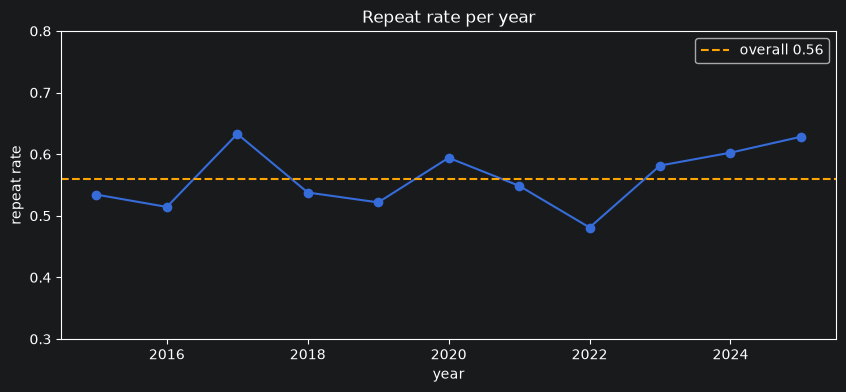

In [44]:
plt.figure(figsize=(10, 4))
plt.plot(by_year.index, by_year["repeat rate"], marker="o")
plt.axhline(df[target_col].mean(), color="orange", linestyle="--", label=f"overall {df[target_col].mean():.2f}")
plt.ylim(0.3, 0.8)
plt.xlabel("year")
plt.ylabel("repeat rate")
plt.title("Repeat rate per year")
plt.legend()
plt.show()

The repeat rate is not the same every year: it goes from 0.48 (2022) to 0.63 (2017 and 2025), and the last years are above the overall average. This means the population changes over time (population drift), so the clients the model will see in the future are not exactly the same as the ones it learned from. 2025 only has 78 rows because the data ends in February 2025.

In [36]:
# how many of the recent purchases come from clients we already knew?
recent = purchase_dates >= "2023-01-01"
old_clients = set(df.loc[~recent, "customer_id"])
recent_clients = set(df.loc[recent, "customer_id"])

print(f"Purchases from 2023 onwards: {recent.sum():,}")
print(f"Made by clients who already bought before 2023: {df.loc[recent, 'customer_id'].isin(old_clients).mean():.1%}")
print(f"Clients active since 2023: {len(recent_clients)} | new clients: {len(recent_clients - old_clients)}")

Purchases from 2023 onwards: 1,602
Made by clients who already bought before 2023: 89.5%
Clients active since 2023: 261 | new clients: 57


Almost 90% of the recent purchases come from clients that already bought before. Clients keep coming back over many years, so a future purchase will usually belong to a client that already has history in the data.

In [37]:
# median of some variables in 3 periods
period = pd.cut(purchase_dates.dt.year, bins=[2014, 2018, 2022, 2025], labels=["2015-2018", "2019-2022", "2023-2025"])
cols_time = ["Total a Pagar", "N_ Detalhes", "days_since_previous_purchase", "purchase_count_90d", "spend_90d",
             "purchase_count_365d", "customer_tenure_days", "prior_purchase_count", "prior_total_spend"]
df.groupby(period, observed=True)[cols_time].median().T.round(1)

purchase_date,2015-2018,2019-2022,2023-2025
Total a Pagar,382.1,489.5,634.4
N_ Detalhes,9.0,12.0,15.0
days_since_previous_purchase,49.0,63.0,61.0
purchase_count_90d,1.0,1.0,1.0
spend_90d,147.9,162.6,352.6
purchase_count_365d,3.0,4.0,4.0
customer_tenure_days,309.0,1238.5,2082.0
prior_purchase_count,4.0,15.0,21.0
prior_total_spend,2275.8,9004.0,15013.7


* The **cumulative variables grow with time** just because the company and the clients get older: the median tenure goes from 309 to 2,082 days and the prior total spend from 2,276 € to 15,014 €. The money values also go up (the median invoice goes from 382 € to 634 €).
* The **behaviour variables stay stable**: the days since the previous purchase (around 50-60) and the number of purchases in the last 90 or 365 days almost do not change.

**What we take from this:**
* The model will always predict the future, so the validation should also be **temporal**: train on the older years and validate on the most recent ones. A random split would mix past and future.
* We will **not use the year** of the purchase as a variable, because any future purchase will be in a year the model never saw.
* The cumulative variables will always be a bit higher in the future, so the behaviour variables (recency, frequency in fixed windows) are the safer ones.

### **6.Univariate Analysis**

In [29]:
# How many rows would the 1.5 x IQR rule call outliers, and do those clients buy again?
for col in ["Total a Pagar", "prior_total_spend", "prior_purchase_count", "N_ Detalhes"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    out = s > q3 + 1.5 * (q3 - q1)
    print(f"{col:22s} {100 * out.mean():.1f}% flagged | repeat rate flagged {df.loc[out[out].index, 'repeat_purchase_90d'].mean():.2f}"
          f" vs rest {df.loc[out[~out].index, 'repeat_purchase_90d'].mean():.2f}")

Total a Pagar          9.2% flagged | repeat rate flagged 0.67 vs rest 0.55
prior_total_spend      9.9% flagged | repeat rate flagged 0.84 vs rest 0.53
prior_purchase_count   7.7% flagged | repeat rate flagged 0.97 vs rest 0.53
N_ Detalhes            6.7% flagged | repeat rate flagged 0.64 vs rest 0.55


The rule flags between 7% and 10% of the rows, and these clients buy again much more than the rest (for example 0.97 vs 0.53 for `prior_purchase_count`). They are our best clients, not errors, so we keep them.